<a href="https://colab.research.google.com/github/viansh962/AML_Experiment/blob/main/experiment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# 2	Supervised Learning – Regression: Generate a proper 2-D data set of N points. Split the data set into the Training Data set and Test Data set.
# •	Perform linear regression analysis with Least Squares Method.
# •	Plot the graphs for Training MSE and Test MSE and comment on Curve Fitting and Generalization Error.
# •	Verify the Effect of Data Set Size and Bias-Variance Trade-off.
# •	Apply Cross Validation and plot the graphs for errors.
# •	Apply Subset Selection Method and plot the graphs for errors.
# •	Describe your findings in each case.


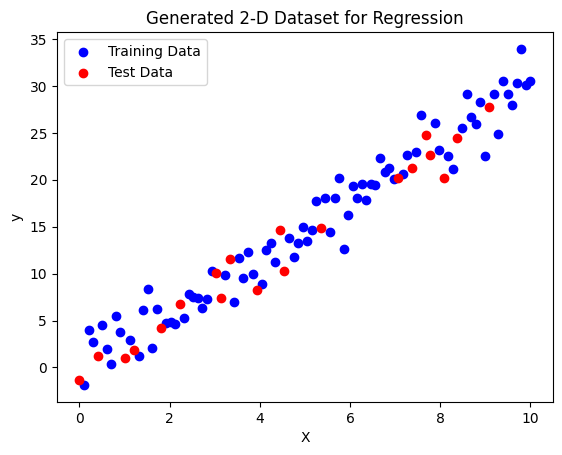

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Step 1: Generate dataset
N = 100  # number of points
X = np.linspace(0, 10, N).reshape(-1, 1)  # feature (independent variable)
y = 3 * X + np.random.randn(N, 1) * 2  # target (dependent variable) with noise

# Step 2: Split dataset into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 3: Visualize
plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.scatter(X_test, y_test, color='red', label='Test Data')
plt.xlabel("X")
plt.ylabel("y")
plt.title("Generated 2-D Dataset for Regression")
plt.legend()
plt.show()


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Generate dataset
N = 100
X = np.linspace(0, 10, N).reshape(-1, 1)
y = 3 * X + np.random.randn(N, 1) * 2   # y = 3x + noise

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [9]:
# Convert to 1-D for easier math
X_train_1d = X_train.ravel()
y_train_1d = y_train.ravel()

# Means
X_mean = np.mean(X_train_1d)
y_mean = np.mean(y_train_1d)

# Slope (m) and Intercept (b)
m = np.sum((X_train_1d - X_mean) * (y_train_1d - y_mean)) / np.sum((X_train_1d - X_mean)**2)
b = y_mean - m * X_mean

print(f"Slope (m): {m:.3f}")
print(f"Intercept (b): {b:.3f}")


Slope (m): 2.924
Intercept (b): 0.491


In [10]:
# Predictions for train & test sets
y_train_pred = m * X_train_1d + b
y_test_pred = m * X_test.ravel() + b


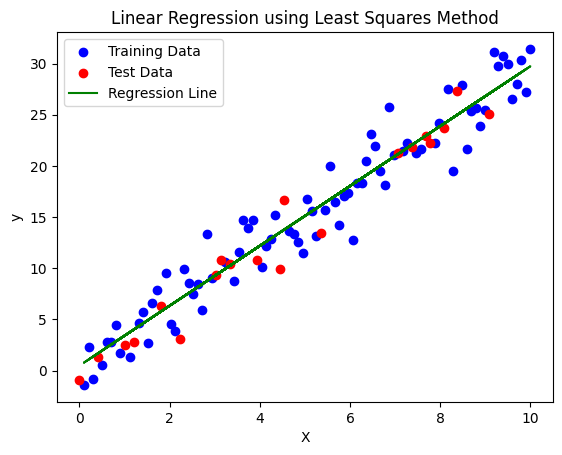

In [11]:
plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.scatter(X_test, y_test, color='red', label='Test Data')

# Regression Line
plt.plot(X_train_1d, y_train_pred, color='green', label='Regression Line')

plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression using Least Squares Method")
plt.legend()
plt.show()


Training MSE: 3.573
Test MSE: 4.166


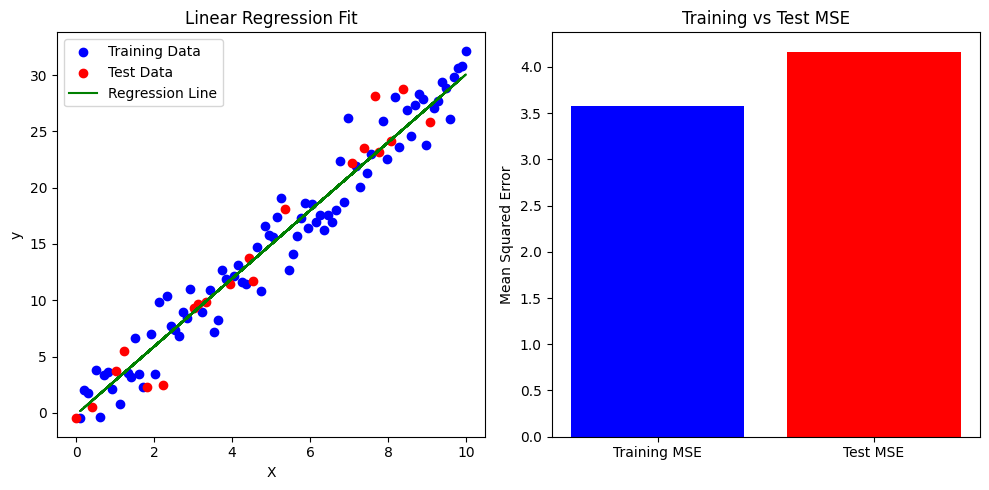

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Step 1: Generate dataset
N = 100
X = np.linspace(0, 10, N).reshape(-1, 1)
y = 3 * X + np.random.randn(N, 1) * 2   # y = 3x + noise

# Step 2: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 3: Least Squares Method
X_train_1d = X_train.ravel()
y_train_1d = y_train.ravel()

X_mean = np.mean(X_train_1d)
y_mean = np.mean(y_train_1d)

# slope and intercept
m = np.sum((X_train_1d - X_mean) * (y_train_1d - y_mean)) / np.sum((X_train_1d - X_mean)**2)
b = y_mean - m * X_mean

# Predictions
y_train_pred = m * X_train_1d + b
y_test_pred = m * X_test.ravel() + b

# Step 4: Compute MSE
train_mse = mean_squared_error(y_train_1d, y_train_pred)
test_mse = mean_squared_error(y_test.ravel(), y_test_pred)

print(f"Training MSE: {train_mse:.3f}")
print(f"Test MSE: {test_mse:.3f}")

# Step 5: Plot
plt.figure(figsize=(10,5))

# Left: regression line
plt.subplot(1,2,1)
plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.scatter(X_test, y_test, color='red', label='Test Data')
plt.plot(X_train_1d, y_train_pred, color='green', label='Regression Line')
plt.xlabel("X"); plt.ylabel("y")
plt.title("Linear Regression Fit")
plt.legend()

# Right: MSE comparison
plt.subplot(1,2,2)
plt.bar(['Training MSE', 'Test MSE'], [train_mse, test_mse], color=['blue', 'red'])
plt.ylabel("Mean Squared Error")
plt.title("Training vs Test MSE")

plt.tight_layout()
plt.show()


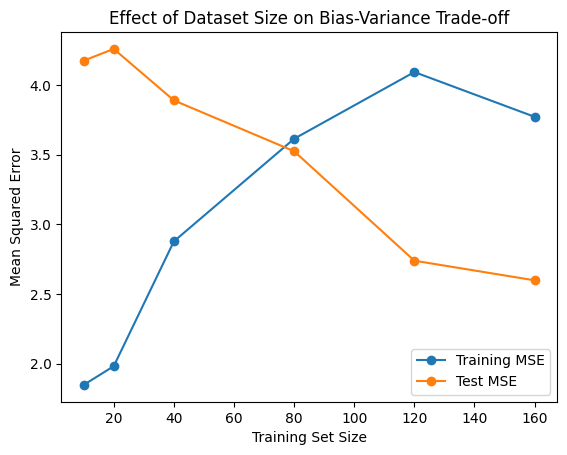

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Step 1: Generate dataset
N = 200
X = np.linspace(0, 10, N).reshape(-1, 1)
y = 3 * X + np.random.randn(N, 1) * 2   # y = 3x + noise

# Step 2: Different training sizes
train_sizes = [10, 20, 40, 80, 120, 160]
train_mse_list = []
test_mse_list = []

for size in train_sizes:
    # Sample subset of training data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, train_size=size, random_state=42
    )

    # Train Linear Regression
    lr = LinearRegression()
    lr.fit(X_train, y_train)
        # Predict
    y_train_pred = lr.predict(X_train)
    y_test_pred = lr.predict(X_test)

    # MSE
    train_mse_list.append(mean_squared_error(y_train, y_train_pred))
    test_mse_list.append(mean_squared_error(y_test, y_test_pred))

# Step 3: Plot errors
plt.plot(train_sizes, train_mse_list, marker='o', label='Training MSE')
plt.plot(train_sizes, test_mse_list, marker='o', label='Test MSE')
plt.xlabel("Training Set Size")
plt.ylabel("Mean Squared Error")
plt.title("Effect of Dataset Size on Bias-Variance Trade-off")
plt.legend()
plt.show()


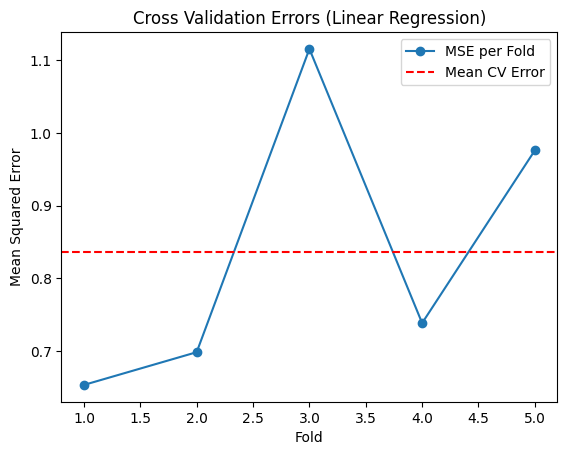

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

# Step 1: Generate dataset
np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

# Step 2: Define Linear Regression Model
model = LinearRegression()

# Step 3: Apply K-Fold Cross Validation (k=5)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
neg_mse_scores = cross_val_score(model, X, y, cv=kf, scoring="neg_mean_squared_error")

# Convert negative MSE to positive
mse_scores = -neg_mse_scores

# Step 4: Plot Cross Validation Errors
plt.plot(range(1, len(mse_scores) + 1), mse_scores, marker='o', label="MSE per Fold")
plt.axhline(np.mean(mse_scores), color='red', linestyle='--', label="Mean CV Error")
plt.xlabel("Fold")
plt.ylabel("Mean Squared Error")
plt.title("Cross Validation Errors (Linear Regression)")
plt.legend()
plt.show()


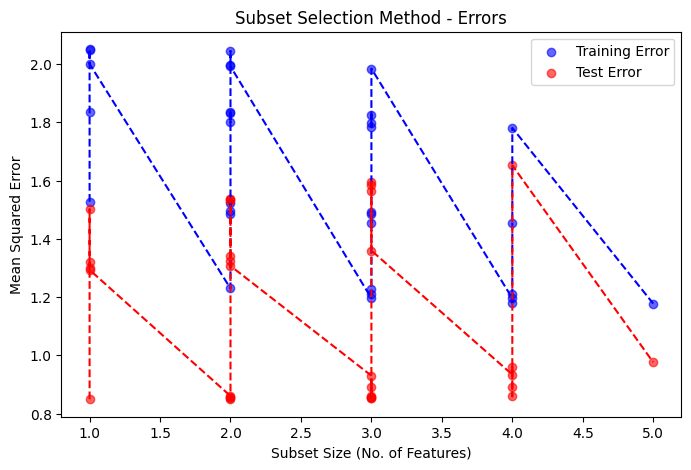

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# Step 1: Generate dataset with multiple features
np.random.seed(42)
X = np.random.rand(100, 5)  # 5 features
y = 3*X[:,0] + 2*X[:,1] + np.random.randn(100)  # only first 2 features matter

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Subset Selection (try all combinations of features)
n_features = X.shape[1]
train_errors = []
test_errors = []
subset_sizes = []

for k in range(1, n_features+1):  # subset size
    for combo in itertools.combinations(range(n_features), k):
        model = LinearRegression()
        model.fit(X_train[:, combo], y_train)

        y_train_pred = model.predict(X_train[:, combo])
        y_test_pred = model.predict(X_test[:, combo])

        train_mse = mean_squared_error(y_train, y_train_pred)
        test_mse = mean_squared_error(y_test, y_test_pred)

        train_errors.append(train_mse)
        test_errors.append(test_mse)
        subset_sizes.append(k)

# Step 3: Plot Errors
plt.figure(figsize=(8,5))
plt.scatter(subset_sizes, train_errors, label="Training Error", color="blue", alpha=0.6)
plt.scatter(subset_sizes, test_errors, label="Test Error", color="red", alpha=0.6)
plt.plot(subset_sizes, train_errors, "--b")
plt.plot(subset_sizes, test_errors, "--r")
plt.xlabel("Subset Size (No. of Features)")
plt.ylabel("Mean Squared Error")
plt.title("Subset Selection Method - Errors")
plt.legend()
plt.show()
